In [1]:
import os, importlib, sys, time

In [2]:
import numpy as np
import scipy.sparse as sparse
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
from tqdm import tqdm

In [3]:
import KECENI

# load data

In [4]:
data_dir = 'data'
save_dir = 'result_true'

In [5]:
data_network = pd.read_feather('%s/network.feather'%(data_dir))
data_latent = pd.read_feather('%s/latent.feather'%data_dir)

In [6]:
data_network

,row,col
0,1,2
1,1,5
2,1,7
3,1,14
4,2,1
...,...,...
3737,999,897
3738,1000,785
3739,1000,891
3740,1000,949


In [7]:
n_node = len(data_latent); n_node

1000

In [8]:
Adj = sparse.csr_matrix((
    np.full(len(data_network), True), 
    (np.array(data_network.row)-1, np.array(data_network.col)-1)
)).toarray()

In [9]:
G = KECENI.Graph(Adj)

# hyperparameters

In [10]:
from hyperparams import delta, HyperAlpha

# counterfactual of interest

In [11]:
i0 = 0

In [12]:
T0s_1 = np.full(n_node, 1)
T0s_0 = np.full(n_node, 0)

In [13]:
T0s_0[G.N1(i0)], T0s_1[G.N1(i0)]

(array([0, 0, 0, 0, 0]), array([1, 1, 1, 1, 1]))

# groundtruth

In [14]:
YTR_1, YTR_0 = (2, -2)
YTR_d = YTR_1 - YTR_0

In [15]:
YTR_0, YTR_1, YTR_d

(-2, 2, 4)

# estimation

In [16]:
n_sim = 80

## - load simulation

In [17]:
lamdas = np.linspace(0, 20, 21)[1:]
hops = np.array([1, 2, 3, 4])

In [18]:
ids_cv = np.zeros(n_sim, dtype=int)

In [19]:
YGs_0 = np.zeros(n_sim); YGs_1 = np.zeros(n_sim); YGs_d = np.zeros(n_sim)
YDRs_0 = np.zeros(n_sim); YDRs_1 = np.zeros(n_sim); YDRs_d = np.zeros(n_sim)

In [20]:
sd0s_bbb_dr = np.zeros((n_sim,)+hops.shape); sd0s_hac_dr = np.zeros((n_sim,)+hops.shape)
sd1s_bbb_dr = np.zeros((n_sim,)+hops.shape); sd1s_hac_dr = np.zeros((n_sim,)+hops.shape)
sdds_bbb_dr = np.zeros((n_sim,)+hops.shape); sdds_hac_dr = np.zeros((n_sim,)+hops.shape)

In [21]:
for i_sim in np.arange(n_sim):
    locals().update(np.load('%s/result_%.3d.npz'%(save_dir,i_sim)))
    YGs_0[i_sim] = YG_0; YGs_1[i_sim] = YG_1; YGs_d[i_sim] = YG_d
    YDRs_0[i_sim] = YDR_0[id_cv]; YDRs_1[i_sim] = YDR_1[id_cv]; YDRs_d[i_sim] = YDR_d[id_cv]
    sd0s_bbb_dr[i_sim] = sd0_bbb_dr[:,id_cv]; sd0s_hac_dr[i_sim] = sd0_hac_dr[:,id_cv]
    sd1s_bbb_dr[i_sim] = sd1_bbb_dr[:,id_cv]; sd1s_hac_dr[i_sim] = sd1_hac_dr[:,id_cv]
    sdds_bbb_dr[i_sim] = sdd_bbb_dr[:,id_cv]; sdds_hac_dr[i_sim] = sdd_hac_dr[:,id_cv]

## - G estimate

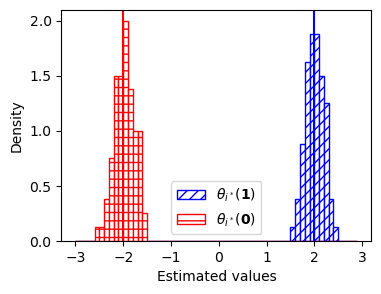

In [22]:
fig = plt.figure(figsize=(4,3))
plt.hist(YGs_1, density=True, bins=np.arange(-3,3,0.1), 
         facecolor='white', edgecolor='blue', hatch="///", 
         label=r'$\theta_{i^*}(\mathbf{1})$')
plt.axvline(YTR_1, color='blue')
plt.hist(YGs_0, density=True, bins=np.arange(-3,3,0.1), 
         facecolor='white', edgecolor='red', hatch="--",
         label=r'$\theta_{i^*}(\mathbf{0})$')
plt.axvline(YTR_0, color='red')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

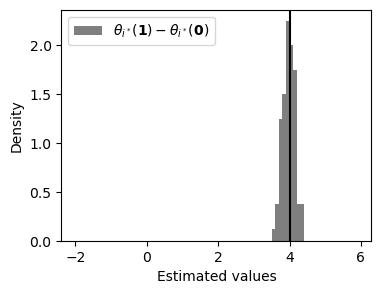

In [23]:
fig = plt.figure(figsize=(4,3))
plt.hist(YGs_d, color='black', alpha=0.5, density=True, bins=np.arange(-2,6,0.1),
         label=r'$\theta_{i^*}(\mathbf{1}) - \theta_{i^*}(\mathbf{0})$')
plt.axvline(YTR_d, color='black')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

In [24]:
np.sqrt(np.mean((YGs_d - YTR_d)**2, 0))

0.16772467810930877

## - kernel EIF

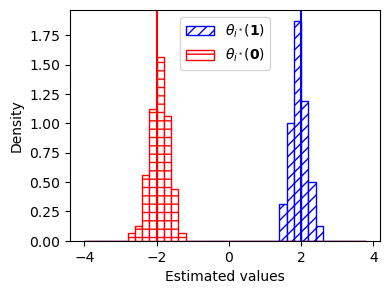

In [25]:
fig = plt.figure(figsize=(4,3))
plt.hist(YDRs_1, density=True, bins=np.arange(-4,4,0.2), 
         facecolor='white', edgecolor='blue', hatch="///", 
         label=r'$\theta_{i^*}(\mathbf{1})$')
plt.axvline(YTR_1, color='blue')
plt.hist(YDRs_0, density=True, bins=np.arange(-4,4,0.2), 
         facecolor='white', edgecolor='red', hatch="--",
         label=r'$\theta_{i^*}(\mathbf{0})$')
plt.axvline(YTR_0, color='red')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

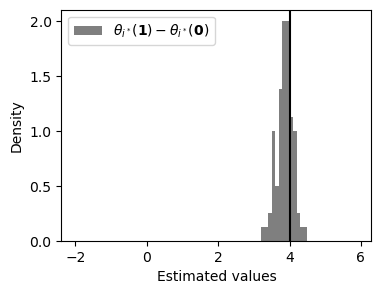

In [26]:
fig = plt.figure(figsize=(4,3))
plt.hist(YDRs_d, color='black', alpha=0.5, 
         density=True, bins=np.arange(-2,6,0.1), 
         label=r'$\theta_{i^*}(\mathbf{1}) - \theta_{i^*}(\mathbf{0})$')
plt.axvline(YTR_d, color='black')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

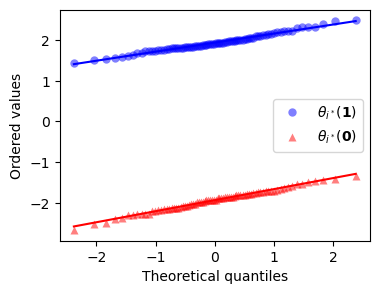

In [27]:
fig = plt.figure(figsize=(4,3)); ax=plt.gca()
stats.probplot(YDRs_1, dist="norm", plot=ax)
stats.probplot(YDRs_0, dist="norm", plot=ax)

ax.get_lines()[0].set_markerfacecolor('blue')
ax.get_lines()[0].set_marker('o')
ax.get_lines()[0].set(alpha=0.5)
ax.get_lines()[0].set_markeredgecolor('none')
ax.get_lines()[1].set(color='blue')
ax.get_lines()[2].set_markerfacecolor('red')
ax.get_lines()[2].set_marker('^')
ax.get_lines()[2].set(alpha=0.5)
ax.get_lines()[2].set_markeredgecolor('none')
ax.get_lines()[3].set(color='red')

ax.legend([ax.get_lines()[0], ax.get_lines()[2]], 
          [r'$\theta_{i^*}(\mathbf{1})$', r'$\theta_{i^*}(\mathbf{0})$'])

plt.xlabel('Theoretical quantiles'); plt.ylabel('Ordered values')
plt.title(''); plt.show()

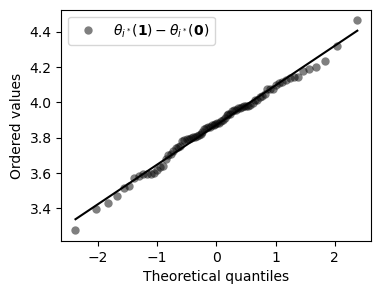

In [28]:
fig = plt.figure(figsize=(4,3)); ax=plt.gca()

stats.probplot(YDRs_d, dist="norm", plot=plt)

ax.get_lines()[0].set_markerfacecolor('black')
ax.get_lines()[0].set(alpha=0.5)
ax.get_lines()[0].set_markeredgecolor('none')
ax.get_lines()[1].set(color='black')

ax.legend([ax.get_lines()[0]], 
          [r'$\theta_{i^*}(\mathbf{1}) - \theta_{i^*}(\mathbf{0})$'])

plt.xlabel('Theoretical quantiles'); plt.ylabel('Ordered values')
plt.title(''); plt.show()

# inference

## - estimated std

In [29]:
np.std(YDRs_0), np.std(YDRs_1), np.std(YDRs_d)

(0.2657463189446635, 0.21838121427614718, 0.21970589458508097)

In [30]:
np.nanmean(sd0s_hac_dr, 0), np.nanmean(sd1s_hac_dr, 0), np.nanmean(sdds_hac_dr, 0) 

(array([0.22122467, 0.22127755, 0.21505417, 0.21050835]),
 array([0.22509692, 0.21940139, 0.21465749, 0.21396675]),
 array([0.21060513, 0.20834217, 0.20747709, 0.20191739]))

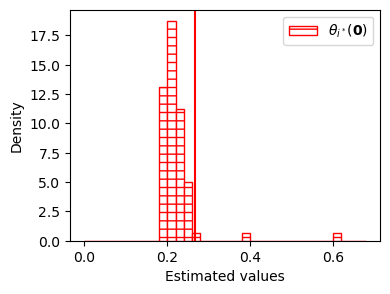

In [31]:
fig = plt.figure(figsize=(4,3))
plt.hist(sd0s_hac_dr[:,0], density=True, 
         facecolor='white', edgecolor='red', hatch="--", bins=np.arange(0,0.7,0.02),
         label=r'$\theta_{i^*}(\mathbf{0})$')
plt.axvline(np.std(YDRs_0), color='red')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

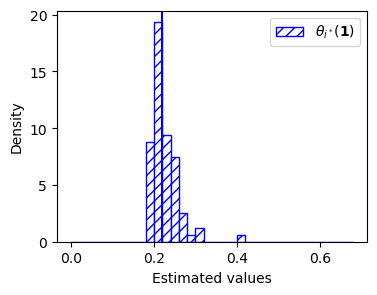

In [32]:
fig = plt.figure(figsize=(4,3))
plt.hist(sd1s_hac_dr[:,0], density=True,  
         facecolor='white', edgecolor='blue', hatch="///", bins=np.arange(0,0.7,0.02),
         label=r'$\theta_{i^*}(\mathbf{1})$')
plt.axvline(np.std(YDRs_1), color='blue')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

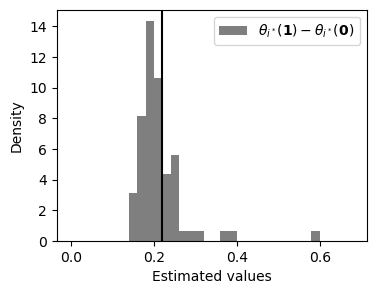

In [33]:
fig = plt.figure(figsize=(4,3))
plt.hist(sdds_hac_dr[:,0], color='black', alpha=0.5, bins=np.arange(0,0.7,0.02),
         density=True,
         label=r'$\theta_{i^*}(\mathbf{1}) - \theta_{i^*}(\mathbf{0})$')
plt.axvline(np.std(YDRs_d), color='black')
plt.xlabel('Estimated values'); plt.ylabel('Density'); plt.legend()

### * coverage

In [34]:
ZDRs_0 = (
    (YDRs_0 - np.mean(YDRs_0))[:,None]
    / sd0s_hac_dr
)

In [35]:
ZDRs_1 = (
    (YDRs_1 - np.mean(YDRs_1))[:,None]
    / sd1s_hac_dr
)

In [36]:
ZDRs_d = (
    (YDRs_d - np.mean(YDRs_d))[:,None]
    / sdds_hac_dr
)

In [37]:
np.nanmean(np.abs(ZDRs_0) <= 2, 0), np.nanmean(np.abs(ZDRs_1) <= 2, 0), np.nanmean(np.abs(ZDRs_d) <= 2, 0)

(array([0.9125, 0.925 , 0.925 , 0.9125]),
 array([0.9625, 0.925 , 0.9125, 0.9   ]),
 array([0.9375, 0.95  , 0.9375, 0.925 ]))

In [38]:
qs = np.linspace(0,1,42)[1:-1]

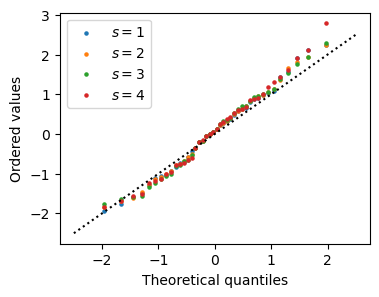

In [39]:
fig = plt.figure(figsize=(4,3))
for i, hop in enumerate(hops):
    plt.scatter(
        stats.norm.ppf(qs),
        np.nanquantile(ZDRs_0[:,i], qs, 0),
        label=r'$s = %d$'%hop, s=5
    )
plt.plot([-2.5,2.5],[-2.5,2.5], linestyle=':', color='black')
plt.xlabel('Theoretical quantiles'); plt.ylabel('Ordered values')
plt.legend()

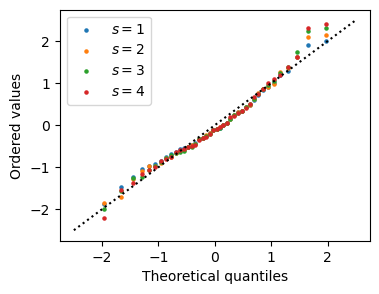

In [40]:
fig = plt.figure(figsize=(4,3))
for i, hop in enumerate(hops):
    plt.scatter(
        stats.norm.ppf(qs),
        np.nanquantile(ZDRs_1[:,i], qs, 0),
        label=r'$s = %d$'%hop, s=5
    )
plt.plot([-2.5,2.5],[-2.5,2.5], linestyle=':', color='black')
plt.xlabel('Theoretical quantiles'); plt.ylabel('Ordered values')
plt.legend()

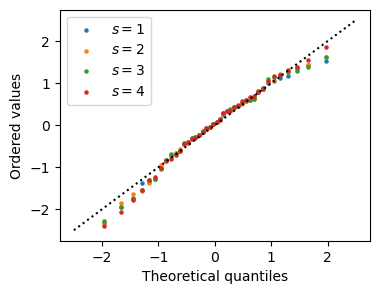

In [41]:
fig = plt.figure(figsize=(4,3))
for i, hop in enumerate(hops):
    plt.scatter(
        stats.norm.ppf(qs),
        np.nanquantile(ZDRs_d[:,i], qs, 0),
        label=r'$s = %d$'%hop, s=5
    )
plt.plot([-2.5,2.5],[-2.5,2.5], linestyle=':', color='black')
plt.xlabel('Theoretical quantiles'); plt.ylabel('Ordered values')
plt.legend()